In [63]:
"""
Replica of Fig. 3a (stellar mass vs redshift) of arXiv:2610.27101,

All values were DIGITISED from the published figure (pixel centroids of the
markers and ends of the error bars; axis calibrated on the tick marks).
Digitisation precision is ~0.01 in z and ~0.01 dex in log M*.
Use the original references for exact values in a publication.

Error bars: (lower, upper) in dex, digitised. Quiescent galaxies have none
in the figure. GN20 and GN20.2b are offset by -0.08 / +0.08 in z in the
paper's figure "for clarity"; here they are stored at their true z and the
same offset is applied only when plotting (PLOT_OFFSET).
"""
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ---------------------------------------------------------------------------
# Dusty star-forming galaxies, z_spec > 4
# ---------------------------------------------------------------------------
DSFG = [
    # name,      z,     logM,  err_lo, err_hi, reference
    ("GN20",     4.055, 10.93, 0.30, 0.17, "Crespo Gomez et al. 2024"),
    ("GN20.2b",  4.056, 11.25, 0.10, 0.09, "Crespo Gomez et al. 2024"),
    #("HDF850.1", 5.183, 10.80, 0.10, 0.10, "Sun et al. 2024"),
    ("", 5.183, 10.80, 0.10, 0.10, "Sun et al. 2024"),
    ("GN10",     5.303, 10.95, 0.09, 0.11, "Lapasia et al. 2026"),
    #("S3",       5.18,  10.31, 0.19, 0.24, "Lapasia et al. 2026"),
    ("",       5.18,  10.31, 0.19, 0.24, "Lapasia et al. 2026"),
]
PLOT_OFFSET = {"GN20": -0.08, "GN20.2b": +0.08}

# ---------------------------------------------------------------------------
# Massive quiescent galaxies, z_spec > 3
# (Carnall et al. 2023a, 2024; de Graaff et al. 2025b; Baker et al. 2025a)
# The figure does not label individual points. Two are identifiable by their
# position: GS-9209 (z = 4.658, Carnall+23a) and RUBIES-EGS-QG-1
# (z = 4.896, de Graaff+25b). The rest are from the sources above.
# ---------------------------------------------------------------------------
QUIESCENT = [
    # z,    logM,   likely ID
    (3.073, 11.30, ""),
    (3.118, 10.54, ""),
    (3.194, 11.11, ""),
    (3.468, 10.40, ""),
    (3.607, 10.87, ""),
    (3.994, 10.98, ""),
    (4.130, 10.55, ""),
    (4.223, 10.46, ""),
    (4.365, 10.52, ""),
    (4.392, 10.37, ""),
    (4.622, 10.98, ""),
    (4.657, 10.55, "GS-9209"),
    (4.897, 11.00, "RUBIES-EGS-QG-1"),
]

# ---------------------------------------------------------------------------
# Leviathan and J0053
# ---------------------------------------------------------------------------
LEVIATHAN = dict(z=4.06, logM=11.35, err_lo=0.22, err_hi=0.15)
J0053 = dict(z=3.9, logM=12.12, err_lo=0.2, err_hi=0.17)

C_BLUE, C_GREEN, C_ORANGE = "#2a78d6", "#1baf7a", "#eb6834"
C_DRC, C_SPT = "#8e44ad", "#d62728"

# ---------------------------------------------------------------------------
# Protocluster members (NOT in the original figure). Masses as published, in
# units of 1e10 Msun: (name, M, sigma); sigma=None -> 1-sigma upper limit.
# ---------------------------------------------------------------------------
# Distant Red Core, z = 4.002 -- Long et al. 2020, Table 2
# (https://arxiv.org/abs/2003.13694). CIGALE, Chabrier IMF.
DRC_Z = 4.002
DRC_MEMBERS = [
    ("DRC-1", 16, 7), ("DRC-2", 8, 6), ("DRC-3", 17, 12),
    ("DRC-6", 3, 2), ("DRC-7", 5, 5), ("DRC-8", 6, 2),
    ("DRC-9", 3, 2), ("DRC-10", 2, 1), ("DRC-11", 2, 1),
]
# DRC-4: only upper-limit photometry ("general estimate", 16e10) -> excluded.
# DRC-5: not spectroscopically confirmed (15 +/- 8 e10) -> optional.
DRC_OPTIONAL = [("DRC-5", 15, 8)]

# SPT2349-56, z = 4.30 -- Hill et al. 2022, Table 2
# (https://arxiv.org/abs/2109.04534). CIGALE, Chabrier IMF.
# Includes core SMGs (C*), northern component (N*), LBG3, LAEs and the
# SPIREc sources ~1.5 Mpc away. N3, NL1-3 are excluded (foreground/unconfirmed).
SPT_Z = 4.30
SPT_MEMBERS = [
    ("C1", 22.2, 21.3), ("C2", 4.5, 1.9), ("C6", 10.9, 3.4),
    ("C7", 3.0, 1.9), ("C8", 11.1, 4.1), ("C10", 1.5, 1.1),
    ("C13", 7.5, 6.8), ("C14", 3.4, 1.3), ("C15", 1.2, 0.6),
    ("C17", 1.2, 0.5), ("C18", 0.6, 0.4), ("C21", 1.0, 0.5),
    ("N1", 4.7, 1.7), ("N2", 1.0, 0.6), ("LBG3", 0.6, 0.4),
    ("LAE4", 0.5, 0.4), ("LAE5", 0.1, 0.1), ("LAE7", 0.4, 0.3),
    ("SPIREc1", 39.3, 34.0), ("SPIREc3", 12.3, 11.0),
]
SPT_UPPER = [("C3", 112.6), ("C4", 24.0), ("C5", 21.8), ("C9", 18.0),
             ("C11", 6.7), ("C19", 4.8), ("SPIREc2", 4.5), ("LAE3", 0.1),
             ("LAE6", 0.8), ("LAE8", 0.8)]


HIGHZ = [  # z, logM, err_lo, err_hi, marker
    (7.04, 10.47, 0.11, 0.11, "s"),   # Xiao+24 sample (red)
    (7.66, 10.48, 0.16, 0.18, "s"),   # Xiao+24 sample (red)
    (7.48, 10.66, 0.08, 0.09, "s"),   # likely Labbe+23 38094
    (9.08, 10.17, 0.23, 0.19, "s"),   # likely Labbe+23 35300 (photo-z)
]


def log_errors(m, s, cap=1.0):
    """Linear M +/- s (same units) -> (log M, err_lo, err_hi) in dex.
    The lower error is capped at `cap` dex when s >= M."""
    lm = np.log10(m)
    lo = lm - np.log10(m - s) if s < m else cap
    return lm + 10, min(lo, cap), np.log10(m + s) - lm


def plot_protoclusters(ax, show_upper_limits=True, include_drc5=False,
                       jitter=0.05, seed=2):
    rng = np.random.default_rng(seed)
    drc = DRC_MEMBERS + (DRC_OPTIONAL if include_drc5 else [])
    for z, members, color, marker in [(DRC_Z, drc, C_DRC, "h"),
                                      (SPT_Z, SPT_MEMBERS, C_SPT, "s")]:
        for _name, m, s in members:
            lm, lo, hi = log_errors(m, s)
            ax.errorbar(z + rng.uniform(-jitter, jitter), lm,
                        yerr=[[lo], [hi]], fmt=marker, ms=6, mfc=color,
                        mec="k", mew=0.5, ecolor=color, elinewidth=0.8,
                        alpha=0.85, zorder=2)
    if show_upper_limits:
        for _name, m in SPT_UPPER:
            ax.errorbar(SPT_Z + rng.uniform(-jitter, jitter),
                        np.log10(m) + 10, yerr=0.15, uplims=True,
                        fmt="s", ms=6, color=C_SPT, mfc="none",
                        elinewidth=0.8, alpha=0.85, zorder=2)


def plot_mass_vs_redshift(ax=None, label_objects=True, protoclusters=True,
                          show_upper_limits=False, include_drc5=False,
                          ylim=(8.8, 12.6)):
    if ax is None:
        fig, ax = plt.subplots(figsize=(5.5, 4.5))
    else:
        fig = ax.figure

    if protoclusters:
        plot_protoclusters(ax, show_upper_limits, include_drc5)

    # Quiescent galaxies
    zq, mq, _ = zip(*QUIESCENT)
    ax.scatter(zq, mq, s=40, c=C_BLUE, edgecolors="k", lw=0.6, zorder=3)

    # Dusty SFGs
    for name, z, m, lo, hi, _ref in DSFG:
        zp = z + PLOT_OFFSET.get(name, 0.0)
        ax.errorbar(zp, m, yerr=[[lo], [hi]], fmt="D", ms=7, mfc=C_GREEN,
                    mec="k", mew=0.6, ecolor=C_GREEN, elinewidth=1.2,
                    zorder=4)
        if label_objects:
            dx, ha = (-0.06, "right") if name == "GN20" else (0.08, "left")
            ax.annotate(name, (zp + dx, m), fontsize=10, ha=ha, va="center")


In [64]:
# Read Mstar vs z

with h5py.File('central_gal_properties_all.hdf5','r') as f:
    redshift = f['z'][()]
    Mstar = f['cluster_0129/Mstar'][()]


/tmp/ipykernel_3766011/2779826584.py:61: RuntimeWarning: divide by zero encountered in log10
  ax.plot(redshift, np.log10(Mstar), lw=3, color='darkblue', label='Central galaxy')


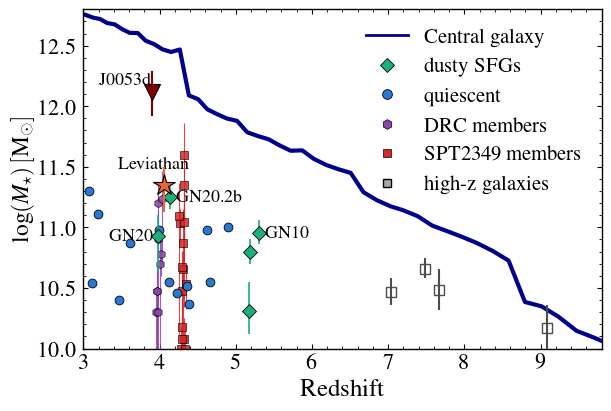

In [65]:
set_style('mnras')

label_objects = True

fig, ax = plt.subplots(1,1,figsize=(6, 4))

fs = 17

# Quiescent galaxies
zq, mq, _ = zip(*QUIESCENT)
ax.scatter(zq, mq, s=40, c=C_BLUE, edgecolors="k", lw=0.6, zorder=3)

# Dusty SFGs
for name, z, m, lo, hi, _ref in DSFG:
    zp = z + PLOT_OFFSET.get(name, 0.0)
    ax.errorbar(zp, m, yerr=[[lo], [hi]], fmt="D", ms=7, mfc=C_GREEN,
                mec="k", mew=0.6, ecolor=C_GREEN, elinewidth=1.2,
                zorder=4)
    if label_objects:
        dx, ha = (-0.06, "right") if name == "GN20" else (0.08, "left")
        ax.annotate(name, (zp + dx, m), fontsize=13, ha=ha, va="center")

# Leviathan
L = LEVIATHAN
ax.errorbar(L["z"], L["logM"], yerr=[[L["err_lo"]], [L["err_hi"]]],
            fmt="none", ecolor=C_ORANGE, elinewidth=1.5, zorder=5)
ax.plot(L["z"], L["logM"], marker="*", ms=16, mfc=C_ORANGE, mec="k",
        mew=0.8, ls="", zorder=7)
if label_objects:
    ax.annotate("Leviathan", (L["z"] - 0.6, L["logM"] + 0.17),
                fontsize=13, fontweight="bold", va="center")

# J0053d
L = J0053
ax.errorbar(L["z"], L["logM"], yerr=[[L["err_lo"]], [L["err_hi"]]],
            fmt="none", ecolor='maroon', elinewidth=1.5, zorder=5)
ax.plot(L["z"], L["logM"], marker="v", ms=12, mfc='maroon', mec="k",
        mew=0.8, ls="", zorder=7)
if label_objects:
    ax.annotate("J0053d", (L["z"] - 0.7, L["logM"] + 0.1),
                fontsize=13, fontweight="bold", va="center")


ax.set_xlim(3.0, 9.8)
ax.set_ylim(10, 12.8)
ax.set_xlabel("Redshift", fontsize=fs+1)
ax.set_ylabel(r"$\log(M_\star) \, [\mathrm{M_\odot}]$", fontsize=fs)
ax.tick_params(direction="in", which="both", top=True, right=True, labelsize=fs-1)
ax.minorticks_on()

# DRC and SPT2349

for z, m, lo, hi, mk in HIGHZ:
    ax.errorbar(z, m, yerr=[[lo], [hi]], fmt=mk, ms=7, mfc="none",
                mec="0.3", ecolor="0.3", zorder=3)


plot_protoclusters(ax, show_upper_limits=False, include_drc5=False)


ax.plot(redshift, np.log10(Mstar), lw=3, color='darkblue', label='Central galaxy')

handles = [Line2D([], [], ls="-", marker=None, lw=2, color='darkblue', label="Central galaxy"),
    Line2D([], [], ls="", marker="D", ms=7, mfc=C_GREEN, mec="k",
           mew=0.6, label=r"dusty SFGs"),
    Line2D([], [], ls="", marker="o", ms=7, mfc=C_BLUE, mec="k",
           mew=0.6, label=r"quiescent"),
        Line2D([], [], ls="", marker="h", ms=7, mfc=C_DRC, mec="k",
           mew=0.5, label="DRC members"),
    Line2D([], [], ls="", marker="s", ms=6, mfc=C_SPT, mec="k",
           mew=0.5, label="SPT2349 members"),
    Line2D([], [], ls="", marker='s', ms=6, color='darkgray', mec="k", label="high-z galaxies")
]
ax.legend(handles=handles, loc="upper right", frameon=False, fontsize=fs-2)


fig.savefig("plots/mass_vs_redshift.png", dpi=400, bbox_inches='tight')